## 제출 정보

- 이름: 예민호

- GitHub ID: yegamanse-cpu

- 작성일: 2026.11.03

- 최종 제출 URL: https://github.com/yegamanse-cpu/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

## 1. 프로젝트 질문

이번엔 completed 주문을 기준으로 아래 3가지를 봄.

### 분석 질문
- 카테고리별 금액 차이가 수량 때문인지 단가 때문인지
- 연령대별 구매 금액은 어떻게 다른가
- 도시별 매출 분포는 어떻게 다른가

### 분석 범위
- 쇼핑몰 거래 데이터 4종 : customers / products / orders / order_items
- 금액 분석 : order_status == completed
- 금액 : line_total = quantity × unit_price

### 계산 기준
- `order_status == "completed"` 적용 여부: O
- `line_total = quantity × unit_price` 확인 여부: O

### 완료 기준
- 세 질문 다 같은 completed 범위로 집계하니까, 카테고리·연령대·도시 합계가 전부 completed 총액과 같아야 완료로 봄

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)

Python 실행 파일: c:\dev\llm-data-analysis-course\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-course
원본 데이터 폴더: C:\dev\llm-data-analysis-course\data\raw
보고서 폴더: C:\dev\llm-data-analysis-course\reports


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)

In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))

,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


In [4]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")

,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\dev\llm-data-analysis-course\data\processed\customers_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\products_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\orders_clean.csv OK
C:\dev\llm-data-analysis-course\data\processed\order_items_clean.csv OK


In [5]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")

,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


In [6]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")

,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 2. 입력 데이터와 전처리 검증

- 사용 원본 파일 : customers / products / orders / order_items
- shape : customers 150행, products 100행, orders 300행, order_items 764행
- 핵심 결측/중복 결과 : 4개 파일 다 0으로 확인
- 전처리 전후 변화 : 행 수는 변화가 없고 컬럼만 늘어남 (orders - order_month·요일 파생, order_items - line_total 파생)

![입력 데이터 검증](images/01.png)


### 나의 해석과 판단
- 결측·중복이 다 0이고 행도 안 줄어서 전처리로 데이터가 사라진 건 없음

### 한계와 추가 확인 사항
- 결측 0은 실습 데이터라 그런 걸 수도 있어서 실제 데이터면 매번 다시 봐야 함

## 3. PK/FK·병합 검증

### PK 결과
- 결측 : 0 
- 중복 : 0 
- PASS/FAIL : PASS

### FK 결과
- 미매칭 : 0
- PASS/FAIL : PASS

### 병합 결과
- validate 관계 : many_to_one / one_to_one
- 병합 전 행 수 : 764 / 474 / 100
- 병합 후 행 수 : 764 / 474 / 100
- 미매칭 : 0
- PASS/FAIL : PASS

### 나의 해석과 판단
- PK 결측 및 중복, FK 미매칭 0으로 연결 문제 없음

In [7]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())

,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-09,2650000,5,530000.0
1,2025-10,16970000,19,893158.0
2,2025-11,11021000,13,847769.0
3,2025-12,21085000,23,916739.0
4,2026-01,14272000,16,892000.0
5,2026-02,4784000,7,683429.0
6,2026-03,18323000,25,732920.0
7,2026-04,11546000,16,721625.0
8,2026-05,16631000,19,875316.0
9,2026-06,12504000,17,735529.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


- LLM을 활용하여 아래의 코드를 생성, 질문에 대한 집계표를 작성함

In [8]:
comp_orders = processed_data["orders"].query("order_status == 'completed'")
line = (
    processed_data["order_items"]
    .merge(comp_orders[["order_id", "customer_id"]], on="order_id", how="inner")
    .merge(processed_data["products"][["product_id", "category"]], on="product_id", how="left")
    .merge(processed_data["customers"][["customer_id", "age", "city"]], on="customer_id", how="left")
)
completed_total = line["line_total"].sum()

category_decomp = (
    line.groupby("category")
    .agg(total_quantity=("quantity", "sum"), total_sales=("line_total", "sum"))
)
category_decomp["avg_unit_price"] = (
    category_decomp["total_sales"] / category_decomp["total_quantity"]
).round(0)
category_decomp["sales_ratio"] = (
    category_decomp["total_sales"] / completed_total * 100
).round(1)
category_decomp = category_decomp.sort_values("total_sales", ascending=False).reset_index()

age_bins = [0, 20, 30, 40, 50, 60, 200]
age_labels = ["10대", "20대", "30대", "40대", "50대", "60대이상"]
line["age_band"] = pd.cut(line["age"], bins=age_bins, labels=age_labels, right=False)
age_sales = (
    line.groupby("age_band", observed=True)
    .agg(total_sales=("line_total", "sum"), customer_count=("customer_id", "nunique"))
)
age_sales["sales_ratio"] = (age_sales["total_sales"] / completed_total * 100).round(1)
age_sales["sales_per_customer"] = (
    age_sales["total_sales"] / age_sales["customer_count"]
).round(0)
age_sales = age_sales.reset_index()

city_sales = (
    line.groupby("city")
    .agg(total_sales=("line_total", "sum"), order_count=("order_id", "nunique"))
)
city_sales["sales_ratio"] = (city_sales["total_sales"] / completed_total * 100).round(1)
city_sales = city_sales.sort_values("total_sales", ascending=False).reset_index()

display(category_decomp)
display(age_sales)
display(city_sales)

for name, df in [("category", category_decomp), ("age", age_sales), ("city", city_sales)]:
    assert np.isclose(df["total_sales"].sum(), completed_total), f"{name} 합계 불일치"
print("completed_total =", completed_total)
print("category / age / city 합계가 모두 completed_total과 일치: PASS")

,category,total_quantity,total_sales,avg_unit_price,sales_ratio
0,스포츠,295,31743000,107603.0,21.3
1,전자기기,259,26400000,101931.0,17.7
2,생활용품,272,23915000,87923.0,16.1
3,뷰티,223,23383000,104857.0,15.7
4,식품,133,16573000,124609.0,11.1
5,도서,149,16389000,109993.0,11.0
6,패션,111,10587000,95378.0,7.1


,age_band,total_sales,customer_count,sales_ratio,sales_per_customer
0,10대,4994000,2,3.4,2497000.0
1,20대,35906000,23,24.1,1561130.0
2,30대,37992000,25,25.5,1519680.0
3,40대,18677000,14,12.5,1334071.0
4,50대,19242000,14,12.9,1374429.0
5,60대이상,32179000,22,21.6,1462682.0


,city,total_sales,order_count,sales_ratio
0,성남,24099000,31,16.2
1,고양,19116000,18,12.8
2,서울,19097000,29,12.8
3,울산,15380000,20,10.3
4,광주,14264000,17,9.6
5,부산,13604000,13,9.1
6,인천,12832000,18,8.6
7,대전,11792000,14,7.9
8,수원,10620000,14,7.1
9,대구,8186000,10,5.5


completed_total = 148990000
category / age / city 합계가 모두 completed_total과 일치: PASS


## 4. 핵심 EDA 결과

### 결과 1 — 카테고리 금액, 수량 vs 단가
- 수치/표 

| category | total_quantity | total_sales | avg_unit_price | sales_ratio |
| --- | --- | --- | --- | --- |
| 0 |	스포츠|	295 |	31743000|	107603.0 |	21.3 |
| 1 |	전자기기 |	259 |	26400000 |	101931.0 |	17.7 |
| 2 |	생활용품 |	272 |	23915000 |	87923.0 |	16.1 |
| 3 |	뷰티 |	223 |	23383000 |	104857.0 |	15.7 |
| 4 |	식품 |	133 |	16573000 |	124609.0 |	11.1 |
| 5 |	도서 |	149 |	16389000 |	109993.0 |	11.0 |
| 6 |	패션 |	111 |	10587000 |	95378.0 |	7.1 |

- 결과 관찰 : 스포츠는 평균단가가 특별히 높지 않으나 수량(약 300개)이 제일 많아 금액 1위. 식품은 단가는 높은데 수량이 적어 중간 정도
- 나의 해석과 판단 : 카테고리 금액 차이는 수량이 더 크게 작용하는 걸로 보여짐
- 업무·분석적 의미: 금액 높은 카테고리는 수량이랑 단가를 같이 봐야 함
- 한계: 할인·반품이 안 들어간 completed 기준으로 실제 수익성과 다를 수 있음

### 결과 2 — 연령대별 구매 금액
- 수치/표 

| age_band | total_sales | customer_count | sales_ratio	| sales_per_customer |
| --- | --- | --- | --- | --- |
| 0	| 10대 | 4994000 | 2 | 3.4 | 2497000.0
| 1	| 20대 | 35906000 | 23 | 24.1 | 1561130.0
| 2	| 30대 | 37992000 | 25 | 25.5 | 1519680.0
| 3	| 40대 | 18677000 | 14 | 12.5 | 1334071.0
| 4	| 50대 | 19242000 | 14 | 12.9 | 1374429.0
| 5	| 60대이상 | 32179000 | 22 | 21.6 | 1462682.0

- 결과 관찰 : 총 금액은 20·30대에 몰리나 1인당 금액은 10대가 가장 큼
- 나의 해석과 판단 : 20·30대 금액이 큰 건 1인당 많이 사서라기보다 고객 수가 많아서로 보임
- 업무·분석적 의미 : 60대 이상도 총 금액 및 1인당 평균금액이 높으므로 타켓팅 대상가능
- 한계 : 전처리 결측 보정(중앙값)의 영향이 있을 수 있음

### 결과 3 — 도시별 매출
- 수치/표 

|	city |	total_sales |	order_count |	sales_ratio |
| --- | --- | --- | --- |
|	0	|	성남	|	24099000	|	31	|	16.2
|	1	|	고양	|	19116000	|	18	|	12.8
|	2	|	서울	|	19097000	|	29	|	12.8
|	3	|	울산	|	15380000	|	20	|	10.3
|	4	|	광주	|	14264000	|	17	|	9.6
|	5	|	부산	|	13604000	|	13	|	9.1
|	6	|	인천	|	12832000	|	18	|	8.6
|	7	|	대전	|	11792000	|	14	|	7.9
|	8	|	수원	|	10620000	|	14	|	7.1
|	9	|	대구	|	8186000	|	10	|	5.5

- 결과 관찰 : 매출이 상위 몇 개 도시에 고르게 퍼져있으며 성남의 경우는 주문 건수도 제일 많음
- 나의 해석과 판단 : 매출 상위 도시는 대체로 주문 건수도 많아서, 매출차이는 주문이 많냐 적냐가 크게 작용하는 걸로 보임
- 업무·분석적 의미 : 성남이 주문건수도 높고 매출도 상위권으로 물류 등의 기반 집중이 필요
- 한계 : 도시별 가입자 수를 모르기 떄문에 잘 구매하는 지역을 단정하기는 어려움

In [9]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")

,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 5. Total consistency와 날짜 검증

- completed source total : 148990000.0
- category total : 148990000.0
- age total :  148990000.0
- city total : 148990000.0
- 총합 일치 여부: O
- completed 주문 날짜 오류 건수: 0
- 날짜 오류 영향 금액: 0

### 불일치가 있었다면 원인
- 해당없음

In [10]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")

공개 결과 금지 컬럼: []
Privacy Gate: PASS


In [11]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")

,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


In [12]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)

,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 141
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 439
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1089


In [13]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")

저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


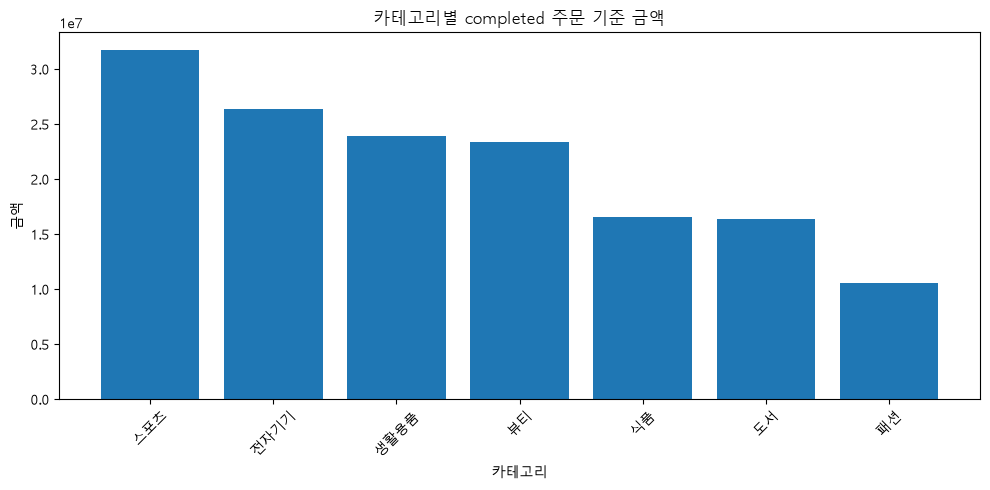

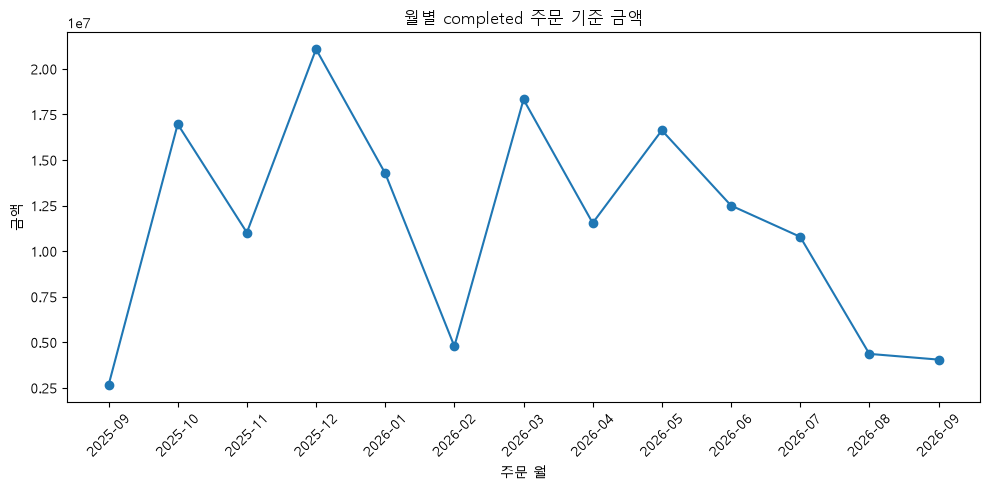

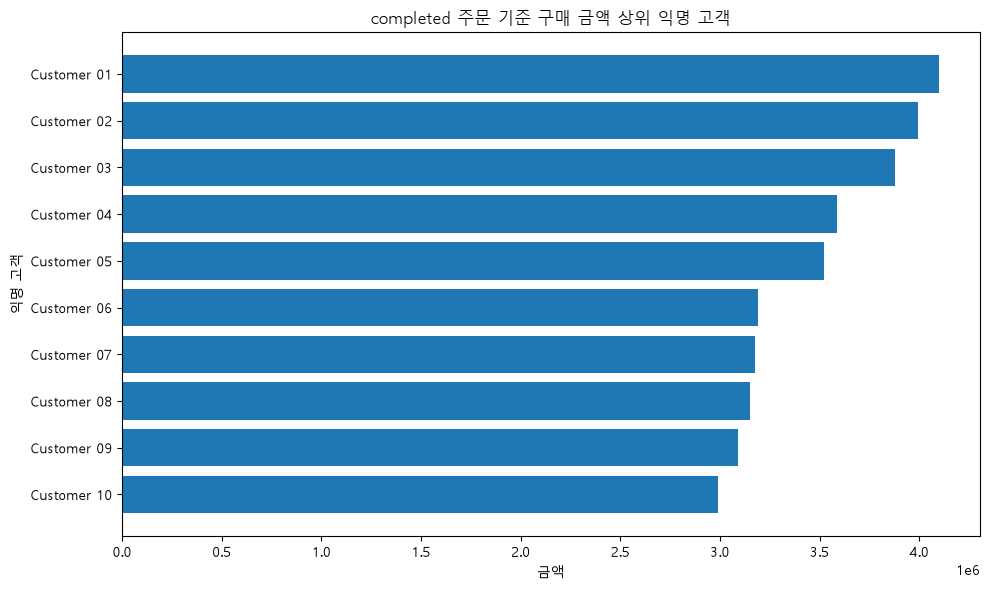

ch08_category_sales.png True 28333
ch08_monthly_sales.png True 81539
ch08_top_customers.png True 47302


In [14]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)

- LLM을 활용하여 도시별 막대그래프 생성

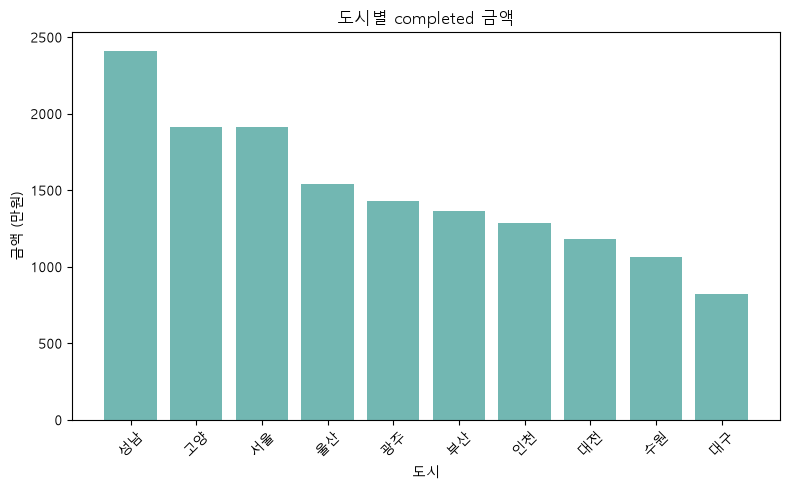

In [15]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

for _font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _font in {f.name for f in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = _font
        break
plt.rcParams["axes.unicode_minus"] = False

city_plot = city_sales.sort_values("total_sales", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(city_plot["city"], city_plot["total_sales"] / 10000, color="#72B7B2")
ax.set_title("도시별 completed 금액")
ax.set_xlabel("도시")
ax.set_ylabel("금액 (만원)")
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

## 6. 대표 시각화

![대표 그래프 1](images/ch08_category_sales.png)
![대표 그래프 2](images/02.png)

### 그래프 선택 이유
- 범주별 금액 비교건으로 막대가 적합

### 그래프와 원본 집계값 일치 여부
- 카테고리는 스포츠가 약 3,170만으로 제일 높고 패션이 약 1,060만으로 제일 낮으므로 집계표와 일치
- 도시는 성남이 약 2,400만으로 제일 높고 대구가 약 820만으로 집계표와 일치

### 그래프에서 직접 관찰한 사실
- 카테고리 막대 : 스포츠가 제일 높고 패션이 제일 낮음
- 도시 막대 : 성남이 살짝 튀고 나머지는 완만하게 내려감

### 그래프만으로 말할 수 없는 것
- 수량/단가, 지역 가입자 수 등은 알 수 없음

In [16]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])

보고서 저장: C:\dev\llm-data-analysis-course\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150                  6
order_items 

In [17]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]

,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


WindowsPath('C:/dev/llm-data-analysis-course/reports/ch08_midterm_report.md')

In [18]:

expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")

ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 7. 개인정보 검증
- 공개 고객 CSV 컬럼 : X
- 원본 `customer_id` 포함 여부 : X
- 이름/이메일/전화번호/주소 포함 여부 : X
- 익명 라벨 방식 : 해당없음
- PASS/FAIL: PASS 

### 나의 판단
- 연령대·도시 그룹화 되어있기 때문에 개인정보 노출불가

## 8. 최종 Validation

`reports/ch08_project_validation.csv`의 결과를 요약합니다. 

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | 4개 PK 결측·중복 0  |
| fk_integrity | PASS | 3개 FK 미매칭 0  |
| merge_checks_pass | PASS | validate + 행 수 보존 + 미매칭 0  |
| line_total_consistency | PASS | 764행 line_total 불일치 0  |
| completed_total_consistency | PASS | source/category/monthly/customer 148,990,000원 |
| category_sales_ratio_pct_sum | PASS | sales_ratio 합계 100.0 |
| completed_rows_with_invalid_order_date | PASS | 날짜 오류 0건  |
| public_customer_columns_safe | PASS | 금지 컬럼 없음 |

### FAIL이 있었다면 수정 내용
- 8개 항목 모두 PASS

## 9. LLM 활용 기록

- 사용 여부: 사용
- 사용 목적: 코딩
- Safe Context: 개인정보는 안 넣고, 연령대·도시 묶음 집계값만 다룸
- Prompt 요약: "completed 기준으로 카테고리 수량/단가, 연령대, 도시 분석 질문을 잡고 검증 방법을 봐 달라"
- 제안 요약: 세 집계를 completed 총액과 맞춰보는 교차검증, 인과 단정 피하기
- 반영/수정/보류: 코딩 반영
- 사람이 검증한 근거: 3가지 질문 집계 합계가 completed 총액과 일치하는지 직접 확인

## 10. 프로젝트 재현 확인
- `python scripts/run_midterm_project.py` 실행 여부 : O
- 재실행 결과: O
- Notebook과 핵심 수치 일치 여부: O
- 생성된 핵심 Evidence 파일 확인 여부: O

![재실행 결과](images/03.png)


### 나의 해석과 판단
- 재현이 안 되면 검증·해석 근거 자체가 흔들리므로 재현가능한 결과가 나와야 함

## 11. 최종 프로젝트 요약

### 핵심 인사이트 3개
1. 카테고리 금액 차이는 단가보다 수량이 더 크게 작용하는 걸로 판단됨
2. 금액은 20·30대에 절반쯤 몰리지만 1인당 금액은 연령대별로 비슷함
3. 도시 매출은 대체로 주문 건수가 많은 도시가 매출도 높음

### 가장 중요한 업무·분석적 의미
- 세 집계(카테고리·연령대·도시) 다 completed 총액과 일치하므로 집계 이상 없음

### 현재 분석의 한계
- 나이 결측 중앙값 대체하였으며, 10대 표본이 부족함 

### 다음 분석 제안
1. 카테고리별 평균단가·수량 
2. 도시별 1인당·1건당 금액 
3. 연령대 × 카테고리 교차 

## 최종 체크
- [x] 질문과 지표가 연결됩니다.
- [x] 원본 데이터에서 다시 시작했습니다.
- [x] PK/FK·병합 검증 근거가 있습니다.
- [x] `line_total` 계산 관계를 확인했습니다.
- [x] 금액성 분석은 completed 범위를 사용했습니다.
- [x] category/연령대/도시 총합이 completed 총액과 일치합니다.
- [x] 날짜 오류를 확인했습니다.
- [x] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [x] 대표 그래프와 원본 집계값을 비교했습니다. 
- [x] 원인 과대 해석이 없습니다.
- [x] 최종 Validation이 모두 PASS입니다.
- [x] 전체 프로젝트를 재실행했습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.